<div align="center">

<h1> <b> IMPLEMENTACIÓN DE LAS FORMULACIONES LAGRANGIANA Y HAMILTONIANA EN LA SOLUCIÓN DE CIRCUITOS ELÉCTRICOS </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Vergara Restrepo <br>
Bernardo Mendoza Montes</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  
</i></h3>
</div>

---

# Planteamiento del problema

Las formulaciones lagrangiana y hamiltoniana surgieron para resolver problemas mecánicos, pero su generalidad conceptual respecto al enfoque newtoniano les permite abordar sistemas físicos ajenos a la mecánica con modificaciones relativamente sencillas. Los circuitos eléctricos son uno de esos sistemas: al construir un lagrangiano equivalente, el formalismo ofrece una descripción geométrica y energética de la dinámica del circuito que complementa la descripción local que dan las leyes de Kirchhoff (Goldstein et al., 2001; Devoret, 1997).

# Objetivos

* Establecer cómo usar las formulaciones lagrangiana y hamiltoniana para resolver circuitos eléctricos.
* Resolver circuitos eléctricos típicos y analizar las diferencias conceptuales con las leyes de Kirchhoff.
* Graficar los diagramas de fase de los circuitos.
* Emplear los desarrollos anteriores para introducir la cuantización de circuitos y explorar la juntura de Josephson.

# Modelo físico

Antes de resolver cualquier circuito es necesario fijar las coordenadas generalizadas y el papel que juega cada elemento del circuito dentro del formalismo de Lagrange y Hamilton.

La coordenada generalizada deja de ser la posición de una partícula y pasa a ser la carga del circuito $q$; su derivada temporal, la "velocidad" generalizada, es la corriente: $\dot q = I$. El análogo de la masa es la inductancia $L$, y en lugar de energía cinética se habla de la energía almacenada en el inductor, $T$:

$$
T = \frac{1}{2}LI^2 = \frac{1}{2}L\dot{q}^2
$$

Las fuentes de voltaje y la resistencia se introducen como fuerzas generalizadas no conservativas. En particular, la resistencia $R$ se modela mediante la función de disipación de Rayleigh, apropiada para fuerzas disipativas proporcionales a la velocidad generalizada (Goldstein et al., 2001; Thornton y Marion, 2003):

$$
\mathcal{F} = \frac{1}{2}RI^2 = \frac{1}{2}R\dot{q}^2
$$

El capacitor actúa como el resorte del circuito: el inverso de la capacitancia, $1/C$, desempeña el papel de la constante de Hooke, y $U$ denota la energía almacenada en el capacitor:

$$
U = \frac{1}{2}\frac{q^2}{C}
$$

# Lagrangiano y solución de circuitos típicos

El primer circuito que vale la pena revisar es el LC (inductor-capacitor). Su lagrangiano es

$$
\mathcal{L} = \frac{1}{2}L\dot{q}^2 - \frac{1}{2}\frac{q^2}{C}
$$

y al aplicar las ecuaciones de Euler-Lagrange se obtiene la ecuación estándar de un oscilador armónico con frecuencia natural $\omega_0 = 1/\sqrt{LC}$ (la derivación completa está en el apéndice):

$$
\ddot{q} + \frac{q}{LC} = 0
$$

El circuito LCR (inductor-capacitor-resistencia) comparte el mismo lagrangiano; la diferencia aparece al incluir la función de Rayleigh en las ecuaciones de Euler-Lagrange, lo que produce la ecuación de un oscilador amortiguado:

$$
\ddot{q} + \frac{R}{L}\dot{q} + \frac{q}{LC} = 0
$$

Es la misma ecuación que se obtiene al aplicar la ley de voltajes de Kirchhoff a la malla. El enfoque lagrangiano se vuelve especialmente útil al resolver circuitos acoplados, donde escribir directamente las ecuaciones de Kirchhoff para cada malla resulta más engorroso que construir un único lagrangiano del sistema.

# Transición al formalismo hamiltoniano y retrato de fase

Una vez obtenidas las ecuaciones de movimiento a partir del lagrangiano, el siguiente paso es pasar al formalismo hamiltoniano. Mientras que el lagrangiano describe el sistema en términos de posición y velocidad, el hamiltoniano lo hace en términos de posición y momento conjugado, lo que facilita el estudio de la conservación de energía y la construcción del espacio de fases.

### 1. Momento conjugado

Siguiendo la analogía en la que la corriente $\dot q$ equivale a la velocidad y la inductancia $L$ a la masa, el momento conjugado $p$ (que representa físicamente el flujo magnético en el inductor) se define como

$$p = \frac{\partial \mathcal{L}}{\partial \dot{q}} = L\dot{q}.$$

### 2. Construcción del hamiltoniano

La transformada de Legendre lleva del lagrangiano al hamiltoniano. Con $T = \tfrac12 L\dot q^2$ y $U = \tfrac12 q^2/C$, el hamiltoniano $H$ representa la energía total del sistema:

$$H(q, p) = p\dot{q} - \mathcal{L} = \frac{p^2}{2L} + \frac{q^2}{2C}.$$

### 3. Ecuaciones de Hamilton con disipación

En el circuito LCR la naturaleza disipativa de $R$ se incorpora mediante la función de Rayleigh. Las ecuaciones de evolución de primer orden quedan:

1. Evolución de la carga: $\displaystyle \dot{q} = \frac{\partial H}{\partial p} = \frac{p}{L}$
2. Evolución del momento: $\displaystyle \dot{p} = -\frac{\partial H}{\partial q} - \frac{\partial \mathcal{F}}{\partial \dot{q}} = -\frac{q}{C} - \frac{R}{L}p$

Este es un sistema de dos ecuaciones diferenciales de primer orden acopladas. A continuación se integra numéricamente para observar cómo el sistema converge al equilibrio en el diagrama de fase por efecto de la resistencia.

## Simulación numérica del sistema canónico LCR

Las ecuaciones de Hamilton con disipación se integran con `odeint` de SciPy (Virtanen et al., 2020), que emplea el método adaptativo LSODA. Como referencia se usa la solución analítica del caso subamortiguado con $q(0) = q_0$ e $I(0) = 0$,

$$
q(t) = q_0\,e^{-\gamma t}\left[\cos\omega_d t + \frac{\gamma}{\omega_d}\sin\omega_d t\right], \qquad \gamma = \frac{R}{2L}, \quad \omega_d = \sqrt{\omega_0^2 - \gamma^2},
$$

que permite cuantificar el error de la integración numérica.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint, solve_ivp
from IPython.display import Markdown, display  # pies de figura con formato Markdown

In [2]:
# --- Parámetros del circuito LCR (valores ilustrativos en unidades SI) ---
L = 1.2   # Inductancia (H)
C = 0.4   # Capacitancia (F)
R = 0.5   # Resistencia (Ohm); con R = 0 se recupera el ciclo cerrado del circuito LC

# Escalas características del oscilador amortiguado (clasificación en el apéndice)
omega_0 = 1 / np.sqrt(L * C)              # frecuencia natural del circuito LC
gamma = R / (2 * L)                       # tasa de decaimiento de la amplitud
zeta = gamma / omega_0                    # factor de amortiguamiento, (R/2)*sqrt(C/L)
omega_d = np.sqrt(omega_0**2 - gamma**2)  # frecuencia de la oscilación amortiguada

print(f"omega_0 = {omega_0:.3f} rad/s,  zeta = {zeta:.3f}")
print(f"Periodo amortiguado 2*pi/omega_d = {2 * np.pi / omega_d:.2f} s,  "
      f"tiempo de decaimiento 2L/R = {1 / gamma:.2f} s")

omega_0 = 1.443 rad/s,  zeta = 0.144
Periodo amortiguado 2*pi/omega_d = 4.40 s,  tiempo de decaimiento 2L/R = 4.80 s


In [3]:
def sistema_hamiltoniano(y, t, L, C, R):
    """
    Lado derecho de las ecuaciones de Hamilton para el circuito LCR.

    Recibe el estado y = (q, p) -- carga y momento conjugado (flujo magnético)
    -- y devuelve sus derivadas temporales (dq/dt, dp/dt), con la firma
    f(y, t, *args) que espera scipy.integrate.odeint.

    La física:
      dq/dt = p / L        -> la corriente es el momento conjugado sobre la inductancia
      dp/dt = -q/C - R*p/L -> el término -q/C viene del hamiltoniano conservativo
                              (fuerza de "resorte" del capacitor); el término -R*p/L
                              es la disipación que introduce la función de Rayleigh.
    """
    q, p = y
    dqdt = p / L
    dpdt = -q / C - R * p / L
    return [dqdt, dpdt]

In [4]:
# --- Condiciones iniciales y ventana temporal ---
# Carga inicial en el capacitor y corriente inicial nula
y0 = [2.0, 0.0]
t = np.linspace(0, 40, 1500)

# --- Integración numérica ---
solucion = odeint(sistema_hamiltoniano, y0, t, args=(L, C, R))
q_t = solucion[:, 0]
p_t = solucion[:, 1]

# --- Comparación con la solución analítica ---
q0 = y0[0]
q_analitica = q0 * np.exp(-gamma * t) * (np.cos(omega_d * t) + gamma / omega_d * np.sin(omega_d * t))
print(f"Diferencia máxima con la solución analítica, relativa a q0: {np.max(np.abs(q_t - q_analitica)) / q0:.1e}")

Diferencia máxima con la solución analítica, relativa a q0: 4.3e-08


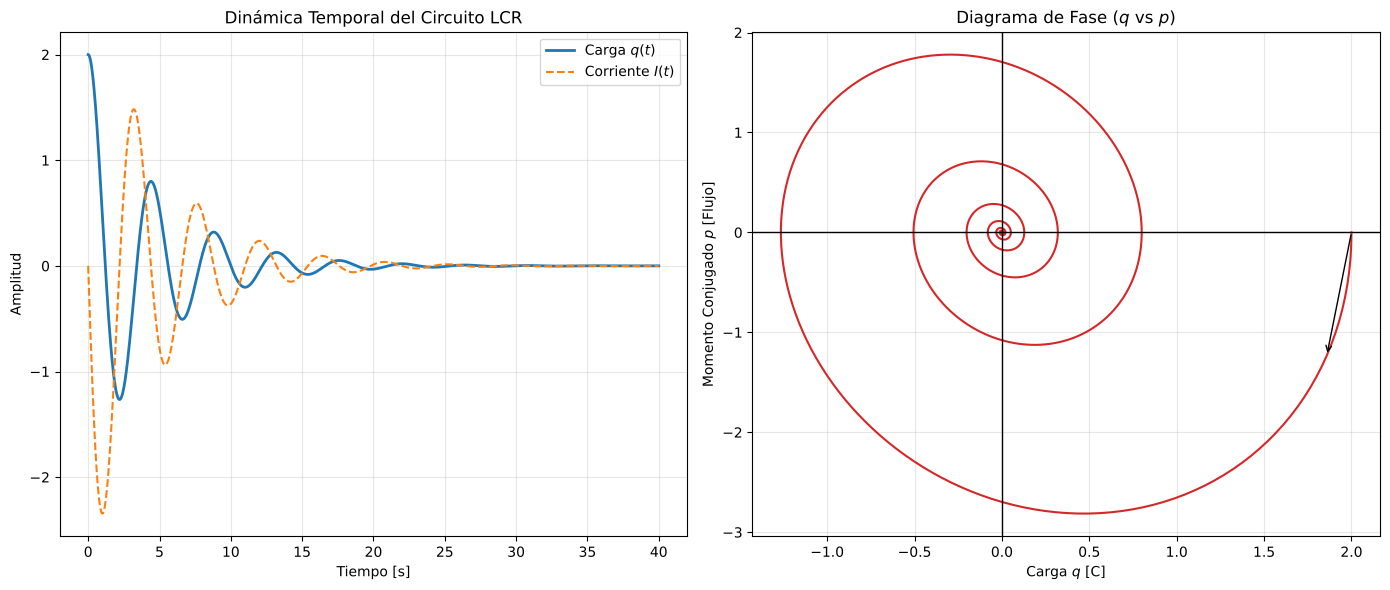

### Figura 1: Dinámica Temporal y Diagrama de Fase del Circuito LCR

Este gráfico muestra la evolución temporal de la carga $q(t)$ y la corriente $I(t)$ en un circuito LCR, evidenciando un comportamiento de oscilador amortiguado. El diagrama de fase $q$ vs $p$ ilustra la trayectoria en espiral que converge al origen debido a la disipación de la resistencia.

In [5]:
# --- Graficación de resultados ---
plt.figure(figsize=(14, 6))

# Subplot 1: evolución temporal de carga y corriente
plt.subplot(1, 2, 1)
plt.plot(t, q_t, label='Carga $q(t)$', color='#1f77b4', lw=2)
plt.plot(t, p_t / L, label='Corriente $I(t)$', color='#ff7f0e', linestyle='--')
plt.title('Dinámica Temporal del Circuito LCR', fontsize=12)
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(alpha=0.3)

# Subplot 2: diagrama de fase (carga vs momento conjugado)
plt.subplot(1, 2, 2)
plt.plot(q_t, p_t, color='#d62728', lw=1.5)
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.title('Diagrama de Fase ($q$ vs $p$)', fontsize=12)
plt.xlabel('Carga $q$ [C]')
plt.ylabel('Momento Conjugado $p$ [Flujo]')
plt.grid(alpha=0.3)

# Flecha que indica el sentido de recorrido de la trayectoria en el espacio de fases
plt.annotate('', xy=(q_t[10], p_t[10]), xytext=(q_t[0], p_t[0]),
             arrowprops=dict(arrowstyle="->", color='black'))

plt.tight_layout()
plt.show()

display(Markdown(
    '### Figura 1: Dinámica Temporal y Diagrama de Fase del Circuito LCR\n\n'
    'Este gráfico muestra la evolución temporal de la carga $q(t)$ y la corriente $I(t)$ '
    'en un circuito LCR, evidenciando un comportamiento de oscilador amortiguado. El '
    'diagrama de fase $q$ vs $p$ ilustra la trayectoria en espiral que converge al origen '
    'debido a la disipación de la resistencia.'
))


# Análisis de resultados

La simulación permite interpretar la dinámica del circuito LCR desde la perspectiva del formalismo canónico. Con $L = 1.2$ H, $C = 0.4$ F y $R = 0.5\ \Omega$, el factor de amortiguamiento es $\zeta = 0.14$, de modo que el circuito es subamortiguado: oscila con un periodo de 4.40 s y su amplitud decae con un tiempo característico $2L/R = 4.8$ s, por lo que en la ventana de 40 s se reduce en un factor $e^{-8.3} \approx 2\times10^{-4}$. La solución numérica coincide con la analítica con una diferencia máxima de $4\times10^{-8}$ relativa a $q_0$.

En la dinámica temporal, tanto la corriente $I(t)$ como la carga $q(t)$ oscilan con una amplitud que decae exponencialmente, como corresponde a un oscilador armónico amortiguado. Cuando el capacitor alcanza su carga máxima la corriente es cero, lo que refleja el traspaso continuo de energía entre el campo eléctrico del capacitor y el campo magnético del inductor.

El diagrama de fase ($q$ vs $p$) es quizás la herramienta más informativa de este formalismo, porque muestra el comportamiento global del sistema en lugar de una sola variable en el tiempo. La trayectoria no se cierra sobre sí misma, como ocurriría en un circuito LC ideal sin resistencia, sino que se enrolla en espiral hacia el origen: la función de Rayleigh modela precisamente esa pérdida continua de energía por efecto de la resistencia. El origen actúa como un atractor del sistema, es decir, el estado de reposo en el que no queda carga almacenada ni flujo magnético residual.

Frente a las leyes de Kirchhoff, el método hamiltoniano ofrece una perspectiva geométrica y energética en lugar de la descripción local, malla por malla, de voltajes y corrientes. Con Kirchhoff se resuelve una ecuación diferencial de segundo orden para una sola función; con Hamilton se describe el circuito como un flujo en el espacio de fases, lo que permite estudiar directamente la estabilidad y la conservación de energía sin necesitar la solución analítica explícita.

## Verificación en unidades SI: solución analítica y balance de energía

Como comprobación independiente, esta sección integra la misma ecuación del circuito RLC, $L\ddot q + R\dot q + q/C = 0$, escrita ahora como ecuación de segundo orden en $q$, con `solve_ivp` (método Runge-Kutta explícito de orden 5(4)) en lugar de `odeint`, y con valores típicos de laboratorio en unidades SI: $L = 1$ mH, $C = 1\ \mu$F y $R = 5\ \Omega$. Además de la carga y la corriente se integra la energía disipada en la resistencia, $W(t) = \int_0^t R I^2\,dt'$, para verificar el balance

$$
H(t) + W(t) = H(0),
$$

que es la forma integrada de $\dot H = -RI^2$ (apéndice, sección 3). La solución numérica se compara también con la solución analítica del caso subamortiguado. Las figuras se guardan en la carpeta `figs_rlc`, relativa al notebook, que se crea si no existe.

In [6]:
# --- Parámetros del circuito RLC en unidades SI ---
L = 1e-3   # henry
C = 1e-6   # farad
R = 5.0    # ohm

omega_0 = 1 / np.sqrt(L * C)
gamma = R / (2 * L)
omega_d = np.sqrt(omega_0**2 - gamma**2)
print(f"f_0 = {omega_0 / (2 * np.pi):.0f} Hz,  zeta = {gamma / omega_0:.3f},  "
      f"periodo = {2 * np.pi / omega_d:.2e} s,  2L/R = {1 / gamma:.1e} s")

f_0 = 5033 Hz,  zeta = 0.079,  periodo = 1.99e-04 s,  2L/R = 4.0e-04 s


In [7]:
def rlc_rhs(t, y, L, C, R):
    """
    Lado derecho de la ecuación del circuito RLC para solve_ivp, f(t, y, *args).

    El estado es y = (q, I, W): carga, corriente y energía disipada en la
    resistencia. De L*q'' + R*q' + q/C = 0 se obtiene
        dq/dt = I,   dI/dt = -(R/L)*I - q/(L*C),   dW/dt = R*I**2.
    """
    q, I, W = y
    return [I, -(R / L) * I - q / (L * C), R * I**2]

In [8]:
# --- Condiciones iniciales y ventana temporal ---
q0 = 1e-6  # carga inicial, en coulombs
I0 = 0.0   # corriente inicial, en amperes (dq/dt)
y0 = [q0, I0, 0.0]

# La envolvente de decaimiento tiene constante de tiempo 2L/R = 4e-4 s. Una ventana
# de 0.003 s cubre unas 7-8 constantes de tiempo (~15 periodos de oscilación), lo
# suficiente para mostrar el transitorio completo.
t_span = (0.0, 0.003)
t_eval = np.linspace(t_span[0], t_span[1], 2000)

# Las tolerancias absolutas se fijan por componente según la escala de cada variable
# (carga ~1e-6 C, corriente ~3e-2 A, energía ~5e-7 J): la tolerancia absoluta por
# defecto de solve_ivp, 1e-6, sería comparable a la propia carga.
sol = solve_ivp(rlc_rhs, t_span, y0, args=(L, C, R), t_eval=t_eval,
                rtol=1e-8, atol=[1e-16, 1e-12, 1e-16])

t = sol.t
q, I, W = sol.y
p = L * I                              # momento conjugado (flujo magnético)
H = 0.5 * L * I**2 + 0.5 * q**2 / C    # energía almacenada (hamiltoniano)

# --- Comparación con la solución analítica y balance de energía ---
q_an = q0 * np.exp(-gamma * t) * (np.cos(omega_d * t) + gamma / omega_d * np.sin(omega_d * t))
I_an = -q0 * omega_0**2 / omega_d * np.exp(-gamma * t) * np.sin(omega_d * t)
print(f"Error máximo en q, relativo a q0:         {np.max(np.abs(q - q_an)) / q0:.1e}")
print(f"Error máximo en I, relativo a max|I|:     {np.max(np.abs(I - I_an)) / np.max(np.abs(I_an)):.1e}")
print(f"Máximo de |H + W - H(0)| / H(0):          {np.max(np.abs(H + W - H[0])) / H[0]:.1e}")
print(f"Energía almacenada al final, H(t_f)/H(0): {H[-1] / H[0]:.1e}")

Error máximo en q, relativo a q0:         6.7e-09
Error máximo en I, relativo a max|I|:     7.6e-09
Máximo de |H + W - H(0)| / H(0):          1.9e-08
Energía almacenada al final, H(t_f)/H(0): 3.2e-07


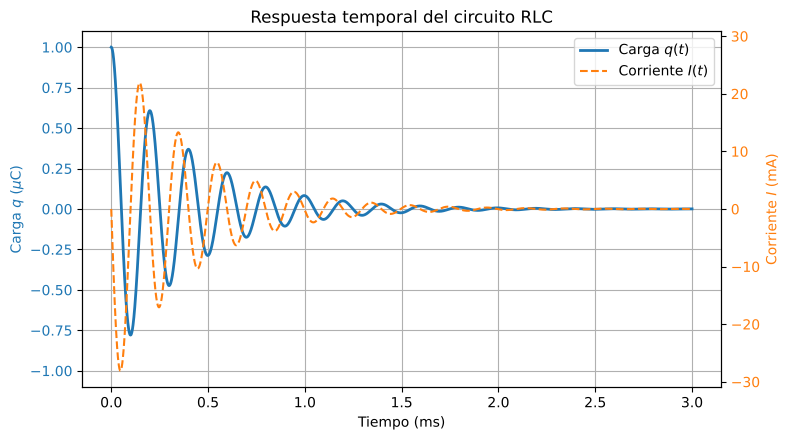

### Figura 2: Respuesta temporal del circuito RLC en unidades SI

Carga y corriente del circuito con $L = 1$ mH, $C = 1\ \mu$F y $R = 5\ \Omega$. La oscilación, de unos 5 kHz, decae con un tiempo característico $2L/R = 0.4$ ms.

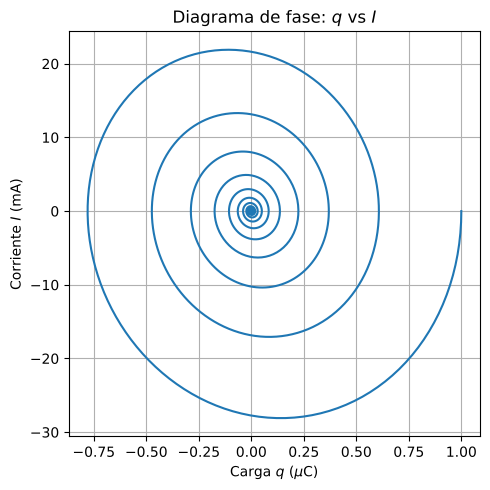

### Figura 3: Diagrama de fase del circuito RLC en unidades SI

La trayectoria en el plano $(q, I)$ es una espiral que converge al origen, como en la simulación canónica (Figura 1), ahora con las escalas de un circuito de laboratorio.

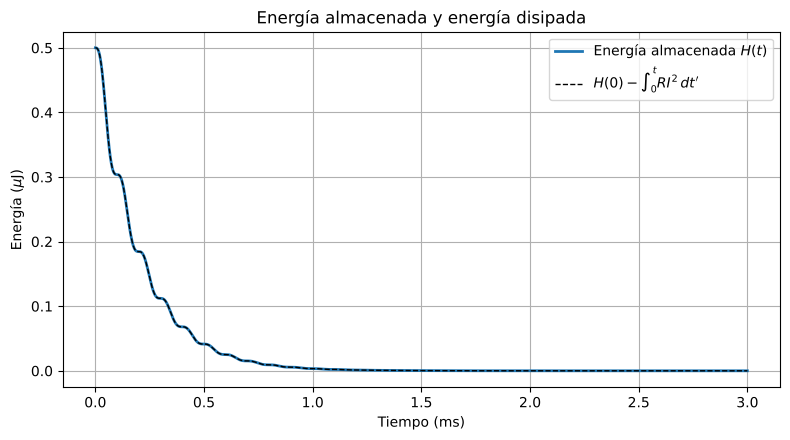

### Figura 4: Balance de energía del circuito RLC

La energía almacenada en el capacitor y el inductor coincide en todo instante con la energía inicial menos la disipada en la resistencia. El decaimiento es escalonado porque la potencia disipada, $RI^2$, se anula cada vez que la corriente pasa por cero.

Figuras guardadas en la carpeta 'figs_rlc'


In [9]:
# Carpeta de salida relativa al notebook
outdir = "figs_rlc"
os.makedirs(outdir, exist_ok=True)

# q(t) e I(t) difieren en varios órdenes de magnitud en unidades SI (microcoulombs
# frente a amperes), así que se usan dos ejes verticales independientes.
fig, ax_q = plt.subplots(figsize=(8, 4.5))
color_q, color_I = '#1f77b4', '#ff7f0e'

ax_q.plot(t * 1e3, q * 1e6, color=color_q, lw=2, label='Carga $q(t)$')
ax_q.set_xlabel('Tiempo (ms)')
ax_q.set_ylabel(r'Carga $q$ ($\mu$C)', color=color_q)
ax_q.tick_params(axis='y', labelcolor=color_q)
ax_q.grid(True)

ax_I = ax_q.twinx()
ax_I.plot(t * 1e3, I * 1e3, color=color_I, lw=1.5, linestyle='--', label='Corriente $I(t)$')
ax_I.set_ylabel('Corriente $I$ (mA)', color=color_I)
ax_I.tick_params(axis='y', labelcolor=color_I)

# Límites simétricos en ambos ejes para que sus ceros coincidan
ax_q.set_ylim(-1.1 * np.max(np.abs(q)) * 1e6, 1.1 * np.max(np.abs(q)) * 1e6)
ax_I.set_ylim(-1.1 * np.max(np.abs(I)) * 1e3, 1.1 * np.max(np.abs(I)) * 1e3)

lineas_q, etiquetas_q = ax_q.get_legend_handles_labels()
lineas_I, etiquetas_I = ax_I.get_legend_handles_labels()
ax_q.legend(lineas_q + lineas_I, etiquetas_q + etiquetas_I, loc='upper right')

plt.title('Respuesta temporal del circuito RLC')
plt.tight_layout()
plt.savefig(os.path.join(outdir, "rlc_q_I.png"), dpi=200)
plt.show()

display(Markdown(
    '### Figura 2: Respuesta temporal del circuito RLC en unidades SI\n\n'
    'Carga y corriente del circuito con $L = 1$ mH, $C = 1\\ \\mu$F y $R = 5\\ \\Omega$. '
    'La oscilación, de unos 5 kHz, decae con un tiempo característico $2L/R = 0.4$ ms.'
))

# Diagrama de fase q vs I
plt.figure(figsize=(5, 5))
plt.plot(q * 1e6, I * 1e3)
plt.xlabel(r'Carga $q$ ($\mu$C)')
plt.ylabel('Corriente $I$ (mA)')
plt.title('Diagrama de fase: $q$ vs $I$')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "rlc_phase_qI.png"), dpi=200)
plt.show()

display(Markdown(
    '### Figura 3: Diagrama de fase del circuito RLC en unidades SI\n\n'
    'La trayectoria en el plano $(q, I)$ es una espiral que converge al origen, como en la '
    'simulación canónica (Figura 1), ahora con las escalas de un circuito de laboratorio.'
))

# Energía almacenada y balance con la energía disipada
plt.figure(figsize=(8, 4.5))
plt.plot(t * 1e3, H * 1e6, lw=2, label='Energía almacenada $H(t)$')
plt.plot(t * 1e3, (H[0] - W) * 1e6, 'k--', lw=1, label=r"$H(0) - \int_0^t R I^2\, dt'$")
plt.xlabel('Tiempo (ms)')
plt.ylabel(r'Energía ($\mu$J)')
plt.title('Energía almacenada y energía disipada')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "rlc_energy.png"), dpi=200)
plt.show()

display(Markdown(
    '### Figura 4: Balance de energía del circuito RLC\n\n'
    'La energía almacenada en el capacitor y el inductor coincide en todo instante con la '
    'energía inicial menos la disipada en la resistencia. El decaimiento es escalonado porque '
    'la potencia disipada, $RI^2$, se anula cada vez que la corriente pasa por cero.'
))

print(f"Figuras guardadas en la carpeta '{outdir}'")

La solución de `solve_ivp` coincide con la analítica con errores relativos de $7\times10^{-9}$ en la carga y $8\times10^{-9}$ en la corriente, y el balance $H + W = H(0)$ se cumple con una discrepancia máxima de $2\times10^{-8}$ de la energía inicial. La energía almacenada no decae de forma suave sino escalonada (Figura 4): la potencia disipada se anula cada vez que la corriente pasa por cero, es decir, cuando toda la energía está en el capacitor. Al final de la ventana de 3 ms queda almacenada una fracción $3\times10^{-7}$ de la energía inicial, del orden de $e^{-Rt/L} = e^{-15}$. Las dos simulaciones, con integradores y escalas distintas, reproducen así la misma física: la solución analítica del oscilador amortiguado y la relación $\dot H = -RI^2$ obtenida con la función de Rayleigh.

# Una aplicación a la mecánica cuántica: la juntura de Josephson

La juntura de Josephson es un paso natural para explorar la cuantización de circuitos. En este dispositivo, dos superconductores están separados por una barrera aislante lo bastante delgada como para permitir el efecto túnel de pares de Cooper (Josephson, 1962).

### El salto al potencial no lineal

En un circuito LC también puede tomarse como coordenada generalizada el flujo magnético $\Phi$ en lugar de la carga. En esa descripción, dual de la anterior, el capacitor aporta el término "cinético", $\tfrac12 C\dot\Phi^2$, y el inductor la energía potencial, $\Phi^2/2L$, cuadrática en el flujo (Devoret, 1997). Una juntura de Josephson se comporta como un inductor no lineal: su energía depende del coseno de la diferencia de fase $\phi$ entre los dos superconductores,

$$U(\phi) = -E_J \cos\phi,$$

donde $E_J$ es la energía de Josephson y la fase está ligada al flujo por $\phi = 2\pi\Phi/\Phi_0$, con $\Phi_0 = h/2e$ el cuanto de flujo magnético (Barone y Paternò, 1982). La corriente que atraviesa la juntura es $I = I_c\sin\phi$, con $I_c = 2\pi E_J/\Phi_0$, y la derivada temporal de la fase fija el voltaje entre sus terminales, $V = (\Phi_0/2\pi)\,\dot\phi$. Junto con la capacitancia propia de la juntura, el hamiltoniano resultante tiene la forma de un péndulo simple: la fase $\phi$ hace de ángulo, la capacitancia de masa y el término $-E_J\cos\phi$ de energía potencial gravitatoria.

Esta analogía es la base del diseño de los qubits superconductores modernos, como el transmon (Koch et al., 2007). En un oscilador armónico todos los niveles de energía están igualmente espaciados, de modo que un pulso resonante con la transición $|0\rangle \to |1\rangle$ también excita la transición $|1\rangle \to |2\rangle$. La anarmonicidad del potencial de la juntura hace que esas transiciones tengan frecuencias distintas, lo que permite aislar los dos primeros niveles y usarlos como los estados $|0\rangle$ y $|1\rangle$ de un qubit.

## Comparación de potenciales: inductor lineal vs juntura de Josephson

Se comparan, sobre una malla de fase, el potencial cuadrático de un inductor lineal y el potencial cosenoidal de la juntura. Para que la comparación aísle la forma del pozo, la inductancia lineal se escoge igual a la inductancia de Josephson, $L_J = (\Phi_0/2\pi)^2/E_J$, de modo que ambos potenciales tienen la misma curvatura en $\phi = 0$. En unidades de $E_J$, y tomando el mínimo como cero de energía, $U_L = \phi^2/2$ y $U_J = 1 - \cos\phi$.

In [10]:
# Malla de valores de la diferencia de fase
phi = np.linspace(-2 * np.pi, 2 * np.pi, 500)

# Energías en unidades de E_J. El inductor lineal tiene L = L_J, de modo que su
# potencial, phi**2/2, coincide con el desarrollo de Taylor de 1 - cos(phi) hasta
# segundo orden: ambos pozos comparten la curvatura en el origen y solo difieren en
# los términos de orden superior, que constituyen la anarmonicidad de la juntura.
Ej = 1.0
U_ind = 0.5 * Ej * phi**2
U_jos = Ej * (1 - np.cos(phi))

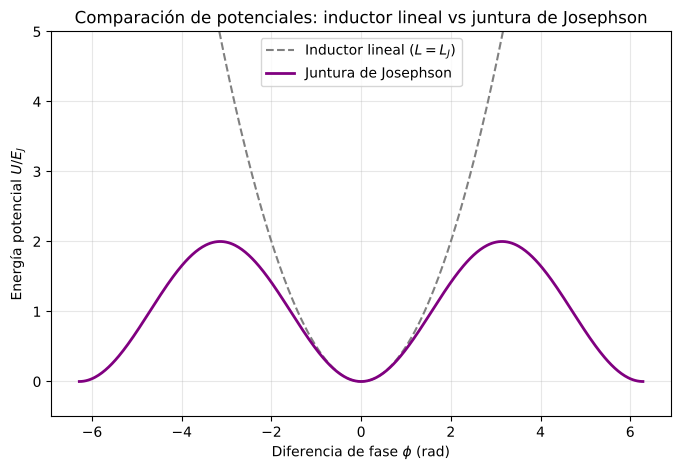

### Figura 5: Comparación de potenciales: inductor lineal vs juntura de Josephson

Potencial cuadrático de un inductor lineal (oscilador armónico) y potencial cosenoidal de una juntura de Josephson (oscilador anarmónico), con la misma curvatura en $\phi = 0$. Cerca del mínimo ambos pozos coinciden; al aumentar $|\phi|$ el potencial de la juntura crece más despacio y es periódico, con máximos en $\phi = \pm\pi$. Esa anarmonicidad hace que los niveles de energía no estén igualmente espaciados, lo que permite aislar los dos primeros para usarlos como qubit.

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(phi, U_ind / Ej, '--', label='Inductor lineal ($L = L_J$)', color='gray')
plt.plot(phi, U_jos / Ej, label='Juntura de Josephson', color='purple', lw=2)

plt.title('Comparación de potenciales: inductor lineal vs juntura de Josephson')
plt.xlabel(r'Diferencia de fase $\phi$ (rad)')
plt.ylabel('Energía potencial $U/E_J$')
plt.ylim(-0.5, 5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(Markdown(
    '### Figura 5: Comparación de potenciales: inductor lineal vs juntura de Josephson\n\n'
    'Potencial cuadrático de un inductor lineal (oscilador armónico) y potencial cosenoidal de una '
    'juntura de Josephson (oscilador anarmónico), con la misma curvatura en $\\phi = 0$. Cerca del '
    'mínimo ambos pozos coinciden; al aumentar $|\\phi|$ el potencial de la juntura crece más despacio '
    'y es periódico, con máximos en $\\phi = \\pm\\pi$. Esa anarmonicidad hace que los niveles de '
    'energía no estén igualmente espaciados, lo que permite aislar los dos primeros para usarlos como qubit.'
))

# Conclusiones

A través de analogías directas entre inductancia y masa, y entre carga y posición, se mostró que los circuitos eléctricos pueden describirse por completo con las formulaciones lagrangiana y hamiltoniana (Goldstein et al., 2001). La función de Rayleigh permite incorporar la resistencia a un formalismo pensado originalmente para sistemas conservativos: el hamiltoniano deja de conservarse y su variación es exactamente la potencia disipada, $\dot H = -RI^2$, como confirma el balance de energía de la simulación en unidades SI, que se cumple con una discrepancia del orden de $10^{-8}$. Las dos simulaciones reproducen la solución analítica del circuito subamortiguado, y el diagrama de fase muestra la espiral que converge al origen, el único estado de equilibrio del circuito.

La juntura de Josephson muestra el mismo formalismo aplicado a un elemento no lineal: tomando como coordenada la diferencia de fase entre los superconductores, la juntura actúa como un inductor anarmónico y el circuito equivale a un péndulo, cuya anarmonicidad es la base de los qubits superconductores. Trabajar con variables conjugadas facilita además la transición hacia sistemas más complejos, como los circuitos acoplados, donde las leyes de Kirchhoff se vuelven algebraicamente pesadas.

# Perspectivas y trabajo futuro

Este trabajo sienta las bases para explorar áreas de la física moderna donde el formalismo canónico es el lenguaje por defecto y no una opción alternativa. Como continuaciones naturales se sugiere:

* **Cuantización de circuitos**: promover las variables $p$ y $q$ del hamiltoniano construido, $H = p^2/2L + q^2/2C$, a operadores que satisfagan la relación de conmutación canónica $[\hat q, \hat p] = i\hbar$ (Devoret, 1997).
* **Junturas de Josephson**: profundizar en circuitos superconductores donde el potencial es sinusoidal en lugar de cuadrático, lo que introduce no linealidades relevantes para fenómenos cuánticos (Barone & Paternò, 1982).
* **Circuitos acoplados**: extender el análisis a sistemas de varias mallas, para examinar cómo el formalismo de Euler-Lagrange maneja simultáneamente múltiples coordenadas generalizadas.

# Apéndice: derivaciones detalladas

### 1) Euler-Lagrange para el circuito LC

Con $q(t)$ como carga generalizada del capacitor y lagrangiano

$$\mathcal{L} = \frac{1}{2}L\dot{q}^2 - \frac{1}{2C}q^2,$$

la ecuación de Euler-Lagrange es

$$\frac{d}{dt}\left(\frac{\partial\mathcal{L}}{\partial\dot{q}}\right) - \frac{\partial\mathcal{L}}{\partial q} = 0.$$

Calculando cada término,

$$\frac{\partial\mathcal{L}}{\partial\dot{q}} = L\dot{q}, \quad \frac{d}{dt}(L\dot{q}) = L\ddot{q}, \quad \frac{\partial\mathcal{L}}{\partial q} = -\frac{q}{C},$$

y sustituyendo se obtiene

$$L\ddot{q} + \frac{q}{C} = 0 \quad\Longrightarrow\quad \ddot{q} + \frac{1}{LC}q = 0,$$

la ecuación característica del oscilador eléctrico LC, de la misma forma que la del sistema masa-resorte.

### 2) Transformada de Legendre y hamiltoniano

El momento conjugado es $p = \partial\mathcal{L}/\partial\dot{q} = L\dot{q}$, de modo que $\dot q = p/L$ y la corriente es $I = \dot q = p/L$. La transformada de Legendre da

$$H(q,p) = p\dot{q} - \mathcal{L} = p\left(\frac{p}{L}\right) - \left[\frac{1}{2}L\left(\frac{p}{L}\right)^2 - \frac{1}{2C}q^2\right] = \frac{p^2}{2L} + \frac{q^2}{2C}.$$

### 3) Energía y disipación con la función de Rayleigh

Al añadir la resistencia $R$ mediante la función de Rayleigh $\mathcal{F} = \tfrac12 R\dot{q}^2$, los términos disipativos entran en la ecuación de Euler-Lagrange como

$$\frac{d}{dt}\left(\frac{\partial\mathcal{L}}{\partial\dot{q}}\right) - \frac{\partial\mathcal{L}}{\partial q} = -\frac{\partial\mathcal{F}}{\partial\dot{q}} = -R\dot{q},$$

lo que produce la ecuación del circuito RLC

$$L\ddot{q} + R\dot{q} + \frac{1}{C}q = 0.$$

La variación temporal del hamiltoniano, que en este caso ya no se conserva, queda relacionada directamente con la disipación:

$$\dot H = -R\dot{q}^2 = -RI^2.$$

### 4) Clasificación del amortiguamiento

La ecuación característica asociada es $Lr^2 + Rr + 1/C = 0$, con discriminante $\Delta = R^2 - 4L/C$. Según su signo, el circuito es:

- **Subamortiguado** si $\Delta < 0$ (soluciones oscilatorias amortiguadas).
- **Críticamente amortiguado** si $\Delta = 0$.
- **Sobreamortiguado** si $\Delta > 0$ (sin oscilación).

En términos del factor de amortiguamiento normalizado $\zeta = \tfrac{R}{2}\sqrt{C/L}$, la condición crítica corresponde a $\zeta = 1$.

---

## Nota sobre el uso del formalismo hamiltoniano con disipación

El formalismo hamiltoniano canónico asume, en su forma estándar, sistemas conservativos. Cuando hay disipación, introducir la función de Rayleigh es una solución práctica para deducir las ecuaciones de movimiento, pero el hamiltoniano resultante ya no se conserva y no constituye una cantidad conservada en sentido estricto. Existen formulaciones más formales para sistemas disipativos, entre ellas el hamiltoniano de Caldirola-Kanai, que introduce una dependencia temporal explícita en el propio hamiltoniano (Caldirola, 1941; Kanai, 1948); los sistemas hamiltonianos de contacto, que generalizan la geometría simpléctica para incluir disipación de forma geométrica (Bravetti, 2017); y el acoplamiento a un reservorio mediante el modelo de Caldeira-Leggett, útil para estudiar decoherencia y cuantización de sistemas disipativos (Caldeira & Leggett, 1983). Estas tres referencias se incluyen como lectura adicional en la bibliografía.

---

# Referencias bibliográficas

### Fuentes académicas primarias

Barone, A., & Paternò, G. (1982). *Physics and applications of the Josephson effect*. Wiley.

Bravetti, A. (2017). Contact Hamiltonian dynamics: The concept and its use. *Entropy*, *19*(10), 535. https://doi.org/10.3390/e19100535

Caldeira, A. O., & Leggett, A. J. (1983). Path integral approach to quantum Brownian motion. *Physica A: Statistical Mechanics and Its Applications*, *121*(3), 587–616. https://doi.org/10.1016/0378-4371(83)90013-4

Caldirola, P. (1941). Forze non conservative nella meccanica quantistica. *Il Nuovo Cimento*, *18*, 393–400. https://doi.org/10.1007/BF02960144

Devoret, M. H. (1997). Quantum fluctuations in electrical circuits. In S. Reynaud, E. Giacobino, & J. Zinn-Justin (Eds.), *Quantum fluctuations: Les Houches Session LXIII* (pp. 351–386). Elsevier.

Goldstein, H., Poole, C. P., & Safko, J. L. (2001). *Classical mechanics* (3rd ed.). Addison-Wesley.

Josephson, B. D. (1962). Possible new effects in superconductive tunnelling. *Physics Letters*, *1*(7), 251–253. https://doi.org/10.1016/0031-9163(62)91369-0

Kanai, E. (1948). On the quantization of the dissipative systems. *Progress of Theoretical Physics*, *3*(4), 440–442. https://doi.org/10.1143/ptp/3.4.440

Koch, J., Yu, T. M., Gambetta, J., Houck, A. A., Schuster, D. I., Majer, J., Blais, A., Devoret, M. H., Girvin, S. M., & Schoelkopf, R. J. (2007). Charge-insensitive qubit design derived from the Cooper pair box. *Physical Review A*, *76*(4), 042319. https://doi.org/10.1103/PhysRevA.76.042319

Thornton, S. T., & Marion, J. B. (2003). *Classical dynamics of particles and systems* (5th ed.). Brooks/Cole.

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., ... SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, *17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2

### Recursos complementarios

Girvin, S. M. (2021, 6 de mayo). *A brief history of superconducting qubits* [Conferencia magistral, QC40: Physics of Computation Conference, MIT Endicott House]. https://www.youtube.com/watch?v=xjlGL4Mvq7A